<a href="https://colab.research.google.com/github/amanda-gabrielly/SolarIA/blob/main/SolarIA.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# ☀️ SolarIA: previsão de geração e economia com energia solar em tempo real

**Disciplina:** Inteligência Artificial · **Curso:** Análise e Desenvolvimento de Sistemas (FICR)

---
## 1. Entendendo o problema
Cada vez mais casas e empresas em Recife instalam energia solar. Mas o gestor **não sabe quanto o sistema vai gerar nos próximos dias**, nem **quanto vai economizar (ou deixar de economizar)** na conta de luz. Dias nublados e chuvosos derrubam a geração, e o prejuízo só aparece quando a conta chega.

**Pergunta que vamos responder:** *com base no clima, é possível prever quanta energia um sistema solar vai gerar e transformar isso em economia (R$) em tempo real?*

## 2. Técnica e família de algoritmo
- **Técnica:** *inferir* (prever) a geração de energia a partir do clima e **comparar** modelos.
- **Família:** **Regressão** (aprendizado supervisionado), porque a resposta é um **número**: a potência gerada (em Watts).
- **Algoritmos comparados:** uma regra simples (modelo base), Regressão Linear e Random Forest.

## 3. Dados públicos utilizados
| Fonte | O que fornece | Uso |
|---|---|---|
| **PVGIS** (Comissão Europeia, JRC) | Histórico **hora a hora** de radiação solar, temperatura, vento e **geração de um sistema solar de 1 kWp** em Recife | Treinar e validar o modelo |
| **Open-Meteo** | Clima **de agora** e **previsão dos próximos 7 dias** para Recife (atualizada várias vezes ao dia) | Previsão em tempo real |
| **Conta de luz da pessoa** (lida pelo Gemini) | Consumo e tarifa reais | Calcular a economia em R$ personalizada |

In [ ]:
!pip install -q gradio google-genai

In [ ]:
# Bibliotecas
import requests
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import TimeSeriesSplit
from sklearn.metrics import mean_absolute_error, r2_score

sns.set_theme(style="whitegrid")
AZUL, LARANJA, AMARELO, CINZA, VERMELHO = "#1F6FEB", "#F97316", "#FACC15", "#B0BEC5", "#E63950"

# 📍 Local: Recife (PE)
LAT, LON = -8.05, -34.90
FUSO = "America/Recife"

## 4. Coletando os dados históricos (PVGIS)
Pedimos à API do PVGIS **5 anos de dados hora a hora** (2019 a 2023) para um sistema solar de **1 kWp** em Recife. Assim, qualquer tamanho de sistema é só multiplicar (um sistema de 3 kWp gera 3×).

Os painéis foram considerados na horizontal (inclinação 0°), para usar exatamente a mesma medida de radiação que a previsão do tempo fornece.

In [ ]:
url_pvgis = "https://re.jrc.ec.europa.eu/api/v5_3/seriescalc"
parametros = {
    "lat": LAT, "lon": LON,
    "startyear": 2019, "endyear": 2023,
    "pvcalculation": 1,     # calcular a geração do sistema
    "peakpower": 1,         # sistema de 1 kWp
    "loss": 14,             # perdas do sistema (cabos, inversor, sujeira): 14%
    "angle": 0,             # painel na horizontal
    "outputformat": "json",
}
resposta = requests.get(url_pvgis, params=parametros, timeout=120)
resposta.raise_for_status()
dados = resposta.json()

df = pd.DataFrame(dados["outputs"]["hourly"])
# O horário vem em UTC no formato "20190101:0010" → convertemos para o horário de Recife
df["time"] = pd.to_datetime(df["time"], format="%Y%m%d:%H%M", utc=True).dt.tz_convert(FUSO)
df = df.rename(columns={"time": "data_hora", "P": "geracao_w", "G(i)": "radiacao",
                        "T2m": "temperatura", "WS10m": "vento", "H_sun": "altura_sol"})
print("Linhas e colunas:", df.shape)
print("Período:", df["data_hora"].min().date(), "até", df["data_hora"].max().date())
df.head()

Linhas e colunas: (43824, 7)
Período: 2018-12-31 até 2023-12-31


,data_hora,geracao_w,radiacao,altura_sol,temperatura,vento,Int
0,2018-12-31 21:05:00-03:00,0.0,0.0,0.0,26.44,3.17,0.0
1,2018-12-31 22:05:00-03:00,0.0,0.0,0.0,26.49,2.97,0.0
2,2018-12-31 23:05:00-03:00,0.0,0.0,0.0,26.55,2.62,0.0
3,2019-01-01 00:05:00-03:00,0.0,0.0,0.0,25.63,2.14,0.0
4,2019-01-01 01:05:00-03:00,0.0,0.0,0.0,25.51,1.59,0.0


## 5. Os dados são válidos? (análise e limpeza)
Antes de treinar, verificamos se os dados fazem sentido:
- Existem **valores faltando**?
- Existem **valores impossíveis**, como geração negativa ou acima da potência do sistema (1 kWp = no máximo ~1.000 W)?
- À **noite** a geração é zero, como deveria ser?

In [ ]:
print("Valores faltando por coluna:")
print(df[["geracao_w", "radiacao", "temperatura", "vento"]].isna().sum(), "\n")

print("Geração negativa:", (df["geracao_w"] < 0).sum())
print("Geração acima de 1.000 W (impossível para 1 kWp):", (df["geracao_w"] > 1000).sum())
noite = df["altura_sol"] <= 0
print(f"Horas de noite: {noite.sum()} | geração média à noite: {df.loc[noite, 'geracao_w'].mean():.2f} W")
if "Int" in df.columns:
    print("Horas com radiação reconstruída pelo PVGIS (Int=1):", int(df["Int"].sum()))

# Limpeza: remove linhas faltando e garante que não existam valores impossíveis
antes = len(df)
df = df.dropna(subset=["geracao_w", "radiacao", "temperatura", "vento"])
df["geracao_w"] = df["geracao_w"].clip(lower=0, upper=1000)
print(f"\nLinhas removidas na limpeza: {antes - len(df)}")

Valores faltando por coluna:
geracao_w      0
radiacao       0
temperatura    0
vento          0
dtype: int64 

Geração negativa: 0
Geração acima de 1.000 W (impossível para 1 kWp): 0
Horas de noite: 22201 | geração média à noite: 0.00 W
Horas com radiação reconstruída pelo PVGIS (Int=1): 0

Linhas removidas na limpeza: 0


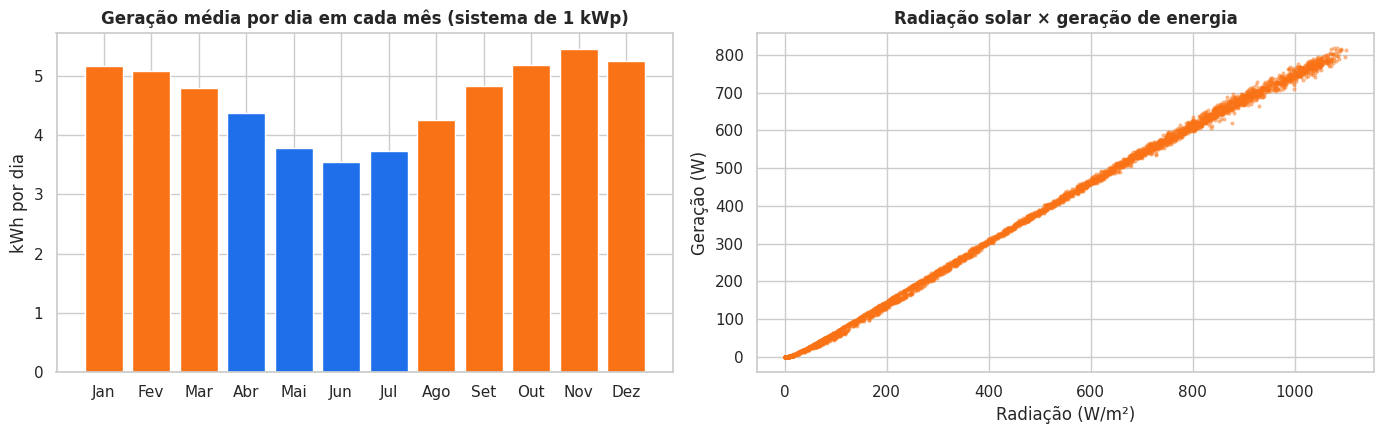

Correlação entre radiação e geração: 1.000
Mês com MENOS geração: Jun (3.54 kWh/dia)
Mês com MAIS geração:  Nov (5.46 kWh/dia)


In [ ]:
# Os dados são coerentes com o clima de Recife?
df["mes"] = df["data_hora"].dt.month
df["hora"] = df["data_hora"].dt.hour
df["dia"] = df["data_hora"].dt.date

diario = df.groupby("dia").agg(kwh=("geracao_w", lambda x: x.sum() / 1000), mes=("mes", "first")).reset_index()
nomes_meses = ["Jan", "Fev", "Mar", "Abr", "Mai", "Jun", "Jul", "Ago", "Set", "Out", "Nov", "Dez"]
por_mes = diario.groupby("mes")["kwh"].mean()

fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
cores_mes = [AZUL if m in [4, 5, 6, 7] else LARANJA for m in por_mes.index]
ax[0].bar([nomes_meses[m - 1] for m in por_mes.index], por_mes.values, color=cores_mes)
ax[0].set_title("Geração média por dia em cada mês (sistema de 1 kWp)", fontweight="bold")
ax[0].set_ylabel("kWh por dia")
amostra = df[df["altura_sol"] > 0].sample(min(4000, (df["altura_sol"] > 0).sum()), random_state=42)
ax[1].scatter(amostra["radiacao"], amostra["geracao_w"], s=4, alpha=0.4, color=LARANJA)
ax[1].set_title("Radiação solar × geração de energia", fontweight="bold")
ax[1].set_xlabel("Radiação (W/m²)"); ax[1].set_ylabel("Geração (W)")
plt.tight_layout(); plt.show()

print(f"Correlação entre radiação e geração: {df['radiacao'].corr(df['geracao_w']):.3f}")
print(f"Mês com MENOS geração: {nomes_meses[por_mes.idxmin() - 1]} ({por_mes.min():.2f} kWh/dia)")
print(f"Mês com MAIS geração:  {nomes_meses[por_mes.idxmax() - 1]} ({por_mes.max():.2f} kWh/dia)")

**Os dados são coerentes:**
- A geração **acompanha a radiação solar** quase em linha reta: mais sol, mais energia.
- Os meses em **azul (abril a julho)** são o **período chuvoso de Recife**, e é justamente quando a geração cai. A primavera e o verão (em laranja) geram mais.

Ou seja, os dados refletem a realidade do clima da cidade e são confiáveis para treinar o modelo.

## 6. Construindo o algoritmo
**Entradas (pistas):** radiação solar, temperatura, vento, hora do dia e mês.
**Saída (o que queremos prever):** geração de energia (W).

**Separação no tempo:** como queremos prever o **futuro**, treinamos com **2019 a 2022** e testamos com **2023**, um ano que o modelo **nunca viu**. Separar aleatoriamente seria "colar na prova", porque o modelo veria horas vizinhas das que vai prever.

In [ ]:
dia = df[df["altura_sol"] > 0].copy()          # só faz sentido prever quando há sol
ENTRADAS = ["radiacao", "temperatura", "vento", "hora", "mes"]
treino = dia[dia["data_hora"].dt.year <= 2022]
teste = dia[dia["data_hora"].dt.year == 2023]
X_treino, y_treino = treino[ENTRADAS], treino["geracao_w"]
X_teste, y_teste = teste[ENTRADAS], teste["geracao_w"]
print(f"Treino: {len(treino)} horas (2019–2022) | Teste: {len(teste)} horas (2023)")

Treino: 17299 horas (2019–2022) | Teste: 4324 horas (2023)


In [ ]:
# Modelo base: uma "regra de bolso" (geração = radiação × fator médio)
fator = (y_treino.sum() / X_treino["radiacao"].sum())

modelos = {
    "Regra simples (base)": None,
    "Regressão Linear": LinearRegression(),
    "Random Forest": RandomForestRegressor(n_estimators=150, max_depth=14, min_samples_leaf=5,
                                           n_jobs=-1, random_state=42),
}

def kwh_por_dia(datas, valores):
    return pd.Series(valores, index=datas.values).groupby(pd.Index(datas.dt.date.values)).sum() / 1000

real_dia = kwh_por_dia(teste["data_hora"], y_teste.values)
resultados, previsoes = [], {}
for nome, modelo in modelos.items():
    if modelo is None:
        prev = X_teste["radiacao"].values * fator
    else:
        modelo.fit(X_treino, y_treino)
        prev = np.clip(modelo.predict(X_teste), 0, 1000)
    previsoes[nome] = prev
    if nome == "Random Forest":
        melhor_teste = modelo
    prev_dia = kwh_por_dia(teste["data_hora"], prev)
    resultados.append({
        "Modelo": nome,
        "Erro médio por hora (W)": mean_absolute_error(y_teste, prev),
        "R² (0 a 1)": r2_score(y_teste, prev),
        "Erro médio por dia (%)": (abs(prev_dia - real_dia).sum() / real_dia.sum()) * 100,
    })

tabela = pd.DataFrame(resultados).set_index("Modelo").round(3)
tabela

,Erro médio por hora (W),R² (0 a 1),Erro médio por dia (%)
Modelo,,,
Regra simples (base),9.572,0.998,1.069
Regressão Linear,7.308,0.999,0.646
Random Forest,1.676,1.000,0.167


**Como ler as métricas:**
- **Erro médio por hora (W):** em média, quantos Watts a previsão erra em cada hora. Quanto **menor**, melhor.
- **R²:** o quanto o modelo explica da variação da geração. **1 = perfeito**, 0 = não explica nada.
- **Erro médio por dia (%):** o erro no **total de energia do dia**. É o que importa para calcular a economia na conta de luz.

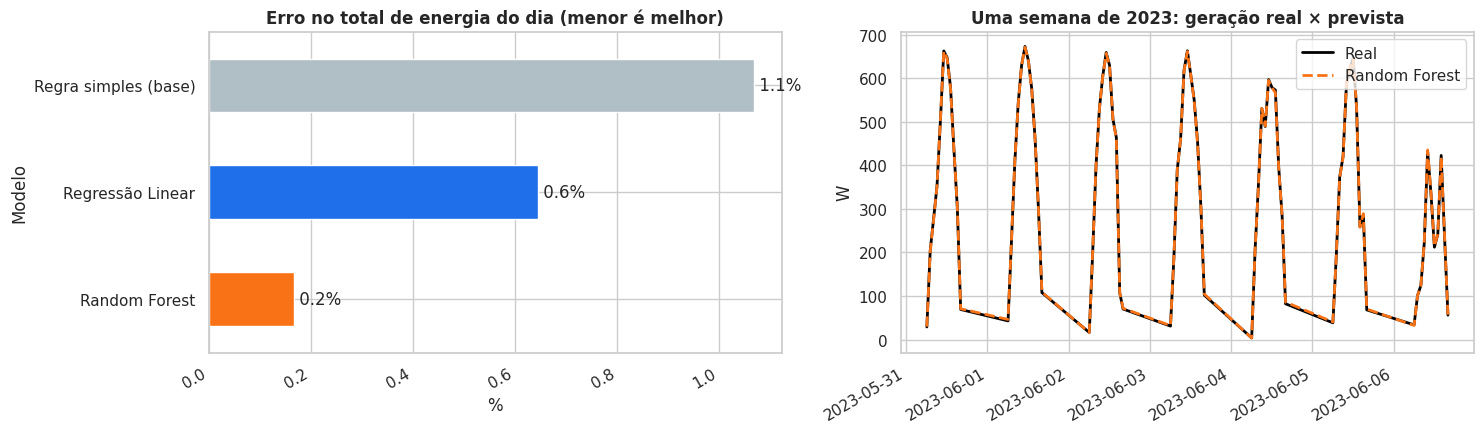

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(15, 4.5))
cores = [CINZA, AZUL, LARANJA]
tabela["Erro médio por dia (%)"].plot(kind="barh", ax=ax[0], color=cores)
ax[0].set_title("Erro no total de energia do dia (menor é melhor)", fontweight="bold"); ax[0].set_xlabel("%")
for i, v in enumerate(tabela["Erro médio por dia (%)"]): ax[0].text(v, i, f" {v:.1f}%", va="center")
ax[0].invert_yaxis()

semana = teste["data_hora"].dt.date.isin(sorted(teste["data_hora"].dt.date.unique())[150:157])
ax[1].plot(teste.loc[semana, "data_hora"], y_teste[semana], color="black", lw=2, label="Real")
ax[1].plot(teste.loc[semana, "data_hora"], previsoes["Random Forest"][semana.values], color=LARANJA, lw=2, ls="--", label="Random Forest")
ax[1].set_title("Uma semana de 2023: geração real × prevista", fontweight="bold"); ax[1].set_ylabel("W")
ax[1].legend(); fig.autofmt_xdate()
plt.tight_layout(); plt.show()

## 7. Validando: o resultado é confiável?
Um único ano de teste pode ter dado "sorte". Usamos então a **validação cruzada para séries temporais**: o modelo é treinado com o passado e testado no período seguinte, **5 vezes**, sempre avançando no tempo. Se o erro for parecido nas 5 rodadas, o modelo é **estável**.

In [ ]:
tscv = TimeSeriesSplit(n_splits=5)
dia_ord = dia.sort_values("data_hora")
X_all, y_all = dia_ord[ENTRADAS], dia_ord["geracao_w"]
validacao = []
for nome, modelo in modelos.items():
    erros, r2s = [], []
    for idx_tr, idx_te in tscv.split(X_all):
        if modelo is None:
            f = y_all.iloc[idx_tr].sum() / X_all["radiacao"].iloc[idx_tr].sum()
            prev = X_all["radiacao"].iloc[idx_te] * f
        else:
            modelo.fit(X_all.iloc[idx_tr], y_all.iloc[idx_tr])
            prev = np.clip(modelo.predict(X_all.iloc[idx_te]), 0, 1000)
        erros.append(mean_absolute_error(y_all.iloc[idx_te], prev))
        r2s.append(r2_score(y_all.iloc[idx_te], prev))
    validacao.append({"Modelo": nome, "Erro médio (W)": round(np.mean(erros), 1),
                      "± variação (W)": round(np.std(erros), 1), "R² médio": round(np.mean(r2s), 3)})
tabela_validacao = pd.DataFrame(validacao).set_index("Modelo")
tabela_validacao

,Erro médio (W),± variação (W),R² médio
Modelo,,,
Regra simples (base),9.8,0.4,0.998
Regressão Linear,7.5,0.3,0.999
Random Forest,2.2,0.8,1.000


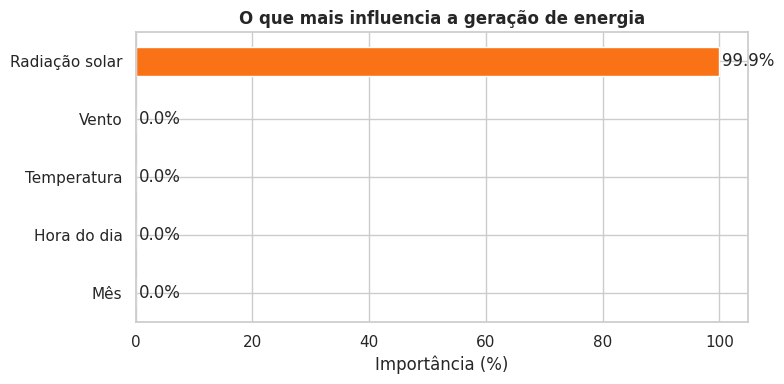

In [ ]:
# Treina o modelo final com TODOS os dados históricos (para usar na previsão ao vivo)
melhor = RandomForestRegressor(n_estimators=150, max_depth=14, min_samples_leaf=5, n_jobs=-1, random_state=42)
melhor.fit(X_all, y_all)

nomes_pt = {"radiacao": "Radiação solar", "temperatura": "Temperatura", "vento": "Vento", "hora": "Hora do dia", "mes": "Mês"}
importancia = pd.Series(melhor.feature_importances_, index=ENTRADAS).rename(nomes_pt).sort_values() * 100
ax = importancia.plot(kind="barh", color=[CINZA] * 4 + [LARANJA], figsize=(8, 4))
ax.set_title("O que mais influencia a geração de energia", fontweight="bold"); ax.set_xlabel("Importância (%)")
for i, v in enumerate(importancia): ax.text(v + 0.5, i, f"{v:.1f}%", va="center")
plt.tight_layout(); plt.show()

### 🧪 Teste de estresse: e se a previsão do tempo errar?
O erro do modelo é muito baixo porque, com a radiação **medida**, a geração é quase uma conta física. Mas, na vida real, vamos usar a radiação **prevista**, e a previsão do tempo erra. Para ser honesto sobre a validade, simulamos previsões do tempo com **10%, 20% e 30% de erro** e medimos quanto isso afeta a previsão de energia do dia.

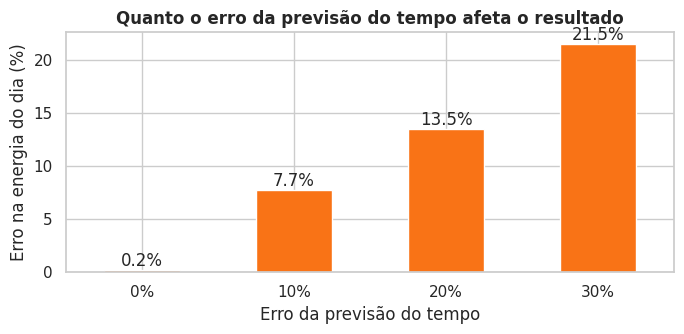

,Erro na energia do dia (%)
Erro da previsão do tempo,
0%,0.2
10%,7.7
20%,13.5
30%,21.5


In [ ]:
rng = np.random.default_rng(42)
estresse = []
for erro_clima in [0, 10, 20, 30]:
    entrada = X_teste.copy()
    # o erro é sorteado por DIA (quando a previsão erra, costuma errar o dia inteiro: veio mais nuvem que o previsto)
    datas = teste["data_hora"].dt.date
    erro_dia = {d: rng.normal(0, erro_clima / 100) for d in datas.unique()}
    entrada["radiacao"] = (entrada["radiacao"] * (1 + datas.map(erro_dia).values)).clip(lower=0)
    prev = np.clip(melhor_teste.predict(entrada), 0, 1000)
    prev_dia = kwh_por_dia(teste["data_hora"], prev)
    estresse.append({"Erro da previsão do tempo": f"{erro_clima}%",
                     "Erro na energia do dia (%)": round((abs(prev_dia - real_dia).sum() / real_dia.sum()) * 100, 1)})
tabela_estresse = pd.DataFrame(estresse).set_index("Erro da previsão do tempo")
ax = tabela_estresse.plot(kind="bar", color=LARANJA, legend=False, rot=0, figsize=(7, 3.5))
ax.set_title("Quanto o erro da previsão do tempo afeta o resultado", fontweight="bold"); ax.set_ylabel("Erro na energia do dia (%)")
for i, v in enumerate(tabela_estresse.iloc[:, 0]): ax.text(i, v, f"{v:.1f}%", ha="center", va="bottom")
plt.tight_layout(); plt.show()
tabela_estresse

## 8. Conclusão da parte experimental
A célula abaixo escreve a conclusão **com os números que saíram nesta execução**.

In [ ]:
rf, base = tabela.loc["Random Forest"], tabela.loc["Regra simples (base)"]
lin = tabela.loc["Regressão Linear"]
vrf = tabela_validacao.loc["Random Forest"]
print("📌 CONCLUSÃO DA PARTE EXPERIMENTAL\n")
print(f"• Os dados são válidos: {len(df):,} horas de dados reais de Recife, sem valores impossíveis,")
print(f"  e coerentes com o clima (o período chuvoso, de abril a julho, gera menos energia).")
print(f"• No teste com 2023 (ano que o modelo nunca viu), o Random Forest errou em média {rf['Erro médio por dia (%)']:.1f}% "
      f"no total de energia do dia,")
print(f"  contra {base['Erro médio por dia (%)']:.1f}% da regra simples e {lin['Erro médio por dia (%)']:.1f}% da Regressão Linear.")
print(f"• R² do Random Forest: {rf['R² (0 a 1)']:.3f} (quanto mais perto de 1, melhor).")
print(f"• Na validação cruzada temporal, o erro foi de {vrf['Erro médio (W)']:.0f} W ± {vrf['± variação (W)']:.0f} W, ou seja, é estável.")
print(f"• O fator mais importante é a {importancia.idxmax().lower()}, como esperado pela física: mais sol, mais energia.")
e20 = tabela_estresse.loc["20%"].iloc[0]
print(f"• Teste de estresse: se a previsão do tempo errar ~20%, o erro na energia do dia sobe para ~{e20:.1f}%.")
print("  Ou seja, o modelo é muito preciso, e o ponto fraco real é a previsão do tempo, não o algoritmo.")
print("\n⚠️ Limitações: os dados históricos do PVGIS são estimados por satélite (não são medições de um sistema real);")
print("   a previsão depende da qualidade da previsão do tempo; consideramos painéis na horizontal.")

📌 CONCLUSÃO DA PARTE EXPERIMENTAL

• Os dados são válidos: 43,824 horas de dados reais de Recife, sem valores impossíveis,
  e coerentes com o clima (o período chuvoso, de abril a julho, gera menos energia).
• No teste com 2023 (ano que o modelo nunca viu), o Random Forest errou em média 0.2% no total de energia do dia,
  contra 1.1% da regra simples e 0.6% da Regressão Linear.
• R² do Random Forest: 1.000 (quanto mais perto de 1, melhor).
• Na validação cruzada temporal, o erro foi de 2 W ± 1 W, ou seja, é estável.
• O fator mais importante é a radiação solar, como esperado pela física: mais sol, mais energia.
• Teste de estresse: se a previsão do tempo errar ~20%, o erro na energia do dia sobe para ~13.5%.
  Ou seja, o modelo é muito preciso, e o ponto fraco real é a previsão do tempo, não o algoritmo.

⚠️ Limitações: os dados históricos do PVGIS são estimados por satélite (não são medições de um sistema real);
   a previsão depende da qualidade da previsão do tempo; consideramos pai

# Parte 2: IA Aplicada
## 9. Previsão AO VIVO para os próximos 7 dias
Agora o modelo sai do laboratório. A cada execução, buscamos na API do **Open-Meteo** a **previsão do tempo mais recente** para Recife, e o Random Forest transforma essa previsão em **energia gerada** e **dinheiro economizado**.

Para saber se a semana será boa ou ruim, comparamos cada dia com um **dia típico** daquele mês (média histórica do PVGIS).

In [ ]:
GERACAO_TIPICA_MES = por_mes.to_dict()   # kWh/dia típico por mês, para 1 kWp

def buscar_previsao_ao_vivo():
    url = "https://api.open-meteo.com/v1/forecast"
    params = {"latitude": LAT, "longitude": LON, "timezone": FUSO, "forecast_days": 7, "wind_speed_unit": "ms",
              "hourly": "shortwave_radiation,temperature_2m,wind_speed_10m,cloud_cover",
              "current": "temperature_2m,shortwave_radiation,cloud_cover"}
    r = requests.get(url, params=params, timeout=30)
    r.raise_for_status()
    j = r.json()
    h = pd.DataFrame(j["hourly"])
    h["data_hora"] = pd.to_datetime(h["time"])
    h = h.rename(columns={"shortwave_radiation": "radiacao", "temperature_2m": "temperatura",
                          "wind_speed_10m": "vento", "cloud_cover": "nuvens"})
    h["hora"], h["mes"] = h["data_hora"].dt.hour, h["data_hora"].dt.month
    return h, j.get("current", {})

def prever_semana(kwp=1.0, tarifa=0.95):
    horas, agora = buscar_previsao_ao_vivo()
    horas[["radiacao", "temperatura", "vento"]] = horas[["radiacao", "temperatura", "vento"]].fillna(0)
    sol = horas["radiacao"] > 0
    horas["geracao_w"] = 0.0
    if sol.any():
        horas.loc[sol, "geracao_w"] = np.clip(melhor.predict(horas.loc[sol, ENTRADAS]), 0, 1000)
    horas["geracao_w"] *= kwp
    dias = horas.groupby(horas["data_hora"].dt.date).agg(
        kwh=("geracao_w", lambda x: x.sum() / 1000), nuvens=("nuvens", "mean"), mes=("mes", "first")).reset_index()
    dias = dias.rename(columns={"data_hora": "dia"})
    dias["kwh_tipico"] = dias["mes"].map(GERACAO_TIPICA_MES) * kwp
    dias["percentual"] = dias["kwh"] / dias["kwh_tipico"] * 100
    dias["economia_rs"] = dias["kwh"] * tarifa
    dias["perda_rs"] = (dias["kwh_tipico"] - dias["kwh"]).clip(lower=0) * tarifa
    dias["alerta"] = np.select([dias["percentual"] >= 90, dias["percentual"] >= 70], ["🟢 Bom", "🟡 Atenção"], "🔴 Ruim")
    return dias, horas, agora

dias, horas, agora = prever_semana(kwp=3, tarifa=0.95)   # exemplo: sistema de 3 kWp
print(f"🕒 Agora em Recife: {agora.get('temperature_2m', '?')} °C | radiação {agora.get('shortwave_radiation', '?')} W/m² | "
      f"nuvens {agora.get('cloud_cover', '?')}%")
print(f"⚡ Geração prevista na semana: {dias['kwh'].sum():.1f} kWh | 💰 Economia prevista: R$ {dias['economia_rs'].sum():.2f} | "
      f"📉 Perda por dias ruins: R$ {dias['perda_rs'].sum():.2f}")
dias[["dia", "kwh", "kwh_tipico", "percentual", "economia_rs", "perda_rs", "alerta"]].round(1)

🕒 Agora em Recife: 31.0 °C | radiação 968.0 W/m² | nuvens 20%
⚡ Geração prevista na semana: 112.7 kWh | 💰 Economia prevista: R$ 107.07 | 📉 Perda por dias ruins: R$ 2.15


,dia,kwh,kwh_tipico,percentual,economia_rs,perda_rs,alerta
0,2026-11-20,15.6,16.4,95.3,14.8,0.7,🟢 Bom
1,2026-11-21,16.7,16.4,101.9,15.8,0.0,🟢 Bom
2,2026-11-22,15.7,16.4,96.1,14.9,0.6,🟢 Bom
3,2026-11-23,15.8,16.4,96.3,15.0,0.6,🟢 Bom
4,2026-11-24,16.5,16.4,100.5,15.6,0.0,🟢 Bom
5,2026-11-25,16.3,16.4,99.5,15.5,0.1,🟢 Bom
6,2026-11-26,16.2,16.4,98.9,15.4,0.2,🟢 Bom


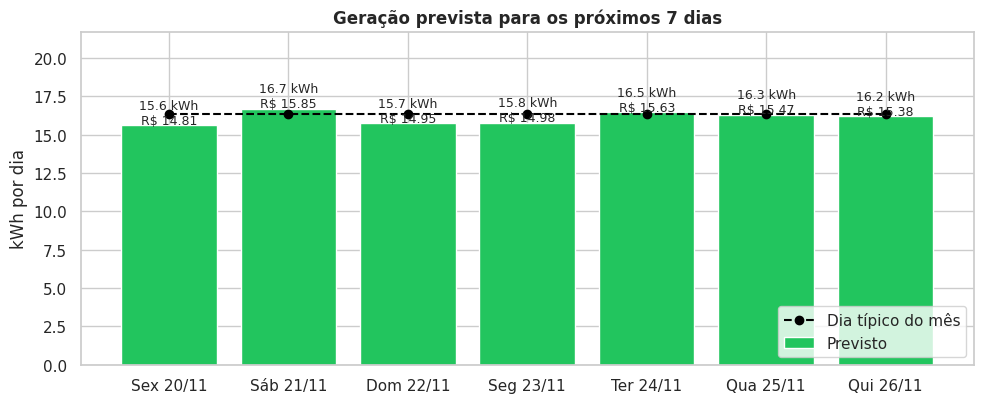

In [ ]:
DIAS_PT = ["Seg", "Ter", "Qua", "Qui", "Sex", "Sáb", "Dom"]
def rotulo_dia(d):
    d = pd.Timestamp(d)
    return f"{DIAS_PT[d.dayofweek]} {d:%d/%m}"

def grafico_semana(dias):
    fig, ax = plt.subplots(figsize=(10, 4.2))
    cores = [("#22C55E" if a.startswith("🟢") else AMARELO if a.startswith("🟡") else VERMELHO) for a in dias["alerta"]]
    rotulos = [rotulo_dia(d) for d in dias["dia"]]
    ax.bar(rotulos, dias["kwh"], color=cores, label="Previsto")
    ax.plot(rotulos, dias["kwh_tipico"], color="black", ls="--", marker="o", label="Dia típico do mês")
    for i, (k, r) in enumerate(zip(dias["kwh"], dias["economia_rs"])):
        ax.text(i, k + 0.1, f"{k:.1f} kWh\nR$ {r:.2f}", ha="center", fontsize=9)
    ax.set_title("Geração prevista para os próximos 7 dias", fontweight="bold")
    ax.set_ylabel("kWh por dia"); ax.legend(loc="lower right"); ax.set_ylim(0, max(dias["kwh"].max(), dias["kwh_tipico"].max()) * 1.3)
    plt.tight_layout()
    return fig

grafico_semana(dias); plt.show()

## 10. Gemini: lendo a conta de luz e escrevendo o relatório do gestor
O Gemini (IA generativa multimodal) faz o que o Random Forest não consegue:
1. 📸 **Lê a foto da conta de luz** e encontra o **consumo** e a **tarifa** reais. Assim, a economia em R$ é calculada com o valor que a pessoa realmente paga.
2. 📄 **Escreve o relatório do gestor**, com a previsão da semana em linguagem simples e recomendações práticas (ex.: em qual dia concentrar o uso de equipamentos que gastam muita energia).

🔑 **Antes de rodar:** no ícone de chave (**Secrets**) da barra lateral, crie o secret `GEMINI_API_KEY` com a sua chave e ative o acesso ao notebook.

In [ ]:
import os, json, re, mimetypes
from google import genai
from google.genai import types

try:
    from google.colab import userdata
    GEMINI_KEY = userdata.get("GEMINI_API_KEY")
except Exception:
    GEMINI_KEY = os.environ.get("GEMINI_API_KEY")
cliente_gemini = genai.Client(api_key=GEMINI_KEY) if GEMINI_KEY else None
MODELOS_GEMINI = ["gemini-flash-latest", "gemini-2.5-flash"]
print("✅ Gemini conectado" if cliente_gemini else "⚠️ Sem chave do Gemini: confira o secret GEMINI_API_KEY")

def chamar_gemini(conteudo, instrucoes, json_saida=False):
    if cliente_gemini is None:
        return None
    config = types.GenerateContentConfig(system_instruction=instrucoes, temperature=0.2 if json_saida else 0.6,
                                         response_mime_type="application/json" if json_saida else None)
    for nome_modelo in MODELOS_GEMINI:
        try:
            r = cliente_gemini.models.generate_content(model=nome_modelo, contents=conteudo, config=config)
            if r.text:
                return r.text.strip()
        except Exception as erro:
            print(f"⚠️ Gemini ({nome_modelo}) falhou: {erro}")
    return None

INSTRUCOES_CONTA = """Você lê contas de energia elétrica brasileiras (foto ou PDF). Devolva SOMENTE um JSON com:
distribuidora (texto), mes_referencia (texto), consumo_kwh (consumo do mês em kWh, número),
valor_total (valor total a pagar em R$, número), tarifa_kwh (preço por kWh com impostos em R$; se não estiver
explícito, calcule valor_total / consumo_kwh), observacoes (frase curta sobre algo relevante, ex.: bandeira tarifária).
Use null para o que não encontrar. Nunca invente valores."""

def ler_conta_de_luz(caminho):
    tipo = mimetypes.guess_type(caminho)[0] or "image/jpeg"
    with open(caminho, "rb") as f:
        parte = types.Part.from_bytes(data=f.read(), mime_type=tipo)
    bruto = chamar_gemini([parte, "Leia esta conta de luz."], INSTRUCOES_CONTA, json_saida=True)
    if not bruto:
        return None
    try:
        return json.loads(re.sub(r"^```(json)?|```$", "", bruto.strip()).strip())
    except json.JSONDecodeError:
        return None

INSTRUCOES_RELATORIO = """Você é a SolarIA, consultora de energia solar que escreve para gestores, em português do Brasil.
Escreva um relatório CURTO (no máximo 8 linhas) com emojis, em tópicos:
1) resumo da semana (geração e economia em R$); 2) dias ruins e o motivo provável (nuvens/chuva);
3) 2 ou 3 recomendações práticas (ex.: concentrar o uso de equipamentos pesados nos dias de mais sol);
4) se houver dados da conta, quanto da conta a energia solar deve cobrir.
Use SOMENTE os números fornecidos. Não invente valores."""

def relatorio_gestor(dias, kwp, tarifa, conta=None):
    tabela_txt = dias[["dia", "kwh", "kwh_tipico", "nuvens", "economia_rs", "perda_rs", "alerta"]].round(1).to_string(index=False)
    extra = f"\nDados da conta de luz: {json.dumps(conta, ensure_ascii=False)}" if conta else ""
    pedido = (f"Sistema solar de {kwp} kWp em Recife, tarifa R$ {tarifa:.2f}/kWh.\n"
              f"Previsão dos próximos 7 dias (kWh, nuvens em %, R$):\n{tabela_txt}{extra}")
    return chamar_gemini(pedido, INSTRUCOES_RELATORIO)

texto = relatorio_gestor(dias, 3, 0.95)
print(texto or "(Sem Gemini: o relatório aparece quando a chave estiver configurada)")

✅ Gemini conectado
⚠️ Gemini (gemini-flash-latest) falhou: 401 UNAUTHENTICATED. {'error': {'code': 401, 'message': 'API key not valid. Please pass a valid API key.', 'status': 'UNAUTHENTICATED', 'details': [{'@type': 'type.googleapis.com/google.rpc.ErrorInfo', 'reason': 'ACCESS_TOKEN_TYPE_UNSUPPORTED', 'metadata': {'method': 'google.ai.generativelanguage.v1beta.GenerativeService.GenerateContent', 'service': 'generativelanguage.googleapis.com'}}]}}
⚠️ Gemini (gemini-2.5-flash) falhou: 401 UNAUTHENTICATED. {'error': {'code': 401, 'message': 'API key not valid. Please pass a valid API key.', 'status': 'UNAUTHENTICATED', 'details': [{'@type': 'type.googleapis.com/google.rpc.ErrorInfo', 'reason': 'ACCESS_TOKEN_TYPE_UNSUPPORTED', 'metadata': {'service': 'generativelanguage.googleapis.com', 'method': 'google.ai.generativelanguage.v1beta.GenerativeService.GenerateContent'}}]}}
(Sem Gemini: o relatório aparece quando a chave estiver configurada)


## 11. Painel do gestor SolarIA (tempo real)
O painel junta tudo:
- ⚡ Ele **busca a previsão do tempo ao vivo** e **se atualiza sozinho a cada 10 minutos**.
- 📸 O gestor **envia a foto da conta de luz**, e o Gemini preenche o consumo e a tarifa.
- 🌲 O Random Forest prevê a geração, e o painel mostra a **economia** e a **perda prevista** em R$.
- 📄 O Gemini escreve o **relatório da semana**.

In [ ]:
# ☀️ PAINEL DO GESTOR SolarIA (tempo real)
import gradio as gr
from datetime import datetime
from zoneinfo import ZoneInfo

LOGO_SVG = """<svg xmlns="http://www.w3.org/2000/svg" viewBox="0 0 64 64">
<defs><linearGradient id="sol" x1="0" y1="0" x2="1" y2="1"><stop offset="0" stop-color="#FDE047"/><stop offset="1" stop-color="#F97316"/></linearGradient></defs>
<g stroke="#F97316" stroke-width="3.5" stroke-linecap="round">
<line x1="24" y1="4" x2="24" y2="10"/><line x1="6" y1="22" x2="12" y2="22"/><line x1="11" y1="9" x2="15" y2="13"/>
<line x1="37" y1="9" x2="33" y2="13"/><line x1="11" y1="35" x2="15" y2="31"/></g>
<circle cx="24" cy="22" r="9" fill="url(#sol)"/>
<path d="M22 34 L58 34 L52 58 L16 58 Z" fill="#1E3A8A"/>
<g stroke="#60A5FA" stroke-width="1.6"><line x1="34" y1="34" x2="29" y2="58"/><line x1="46" y1="34" x2="41" y2="58"/>
<line x1="19" y1="46" x2="55" y2="46"/></g>
</svg>"""

CSS = """
.gradio-container {background: linear-gradient(180deg,#FFFBEB 0%,#FFF7ED 45%,#EFF6FF 100%) !important; font-family:'Nunito','Segoe UI',sans-serif !important;}
.main-wrap {max-width: 1100px; margin: 0 auto;}
#cabecalho {width:100%; box-sizing:border-box; display:flex; flex-direction:column; align-items:center; text-align:center; gap:6px;
            background:#fff; border-radius:24px; padding:18px 24px; border:1px solid #FDE7C7; border-top:5px solid #F97316;
            box-shadow:0 6px 24px rgba(249,115,22,.10);}
#cabecalho svg {width:70px; height:70px;}
#cabecalho h1 {margin:0; font-size:34px; font-weight:800; color:#1E3A8A;}
#cabecalho h1 span {color:#F97316;}
#cabecalho p {margin:0; color:#64748B;}
.cards {display:grid; grid-template-columns:repeat(4,1fr); gap:14px;}
.card {background:#fff; border-radius:20px; padding:16px 18px; border:1px solid #FDE7C7; box-shadow:0 4px 16px rgba(30,58,138,.06);}
.card .rot {color:#64748B; font-size:13px; font-weight:700; text-transform:uppercase; letter-spacing:.4px;}
.card .val {font-size:28px; font-weight:800; color:#1E3A8A; margin-top:4px;}
.card .sub {color:#64748B; font-size:13px; margin-top:2px;}
.card.verde .val {color:#16A34A;} .card.vermelho .val {color:#E63950;} .card.laranja .val {color:#F97316;}
.bloco {background:#fff !important; border-radius:20px !important; border:1px solid #FDE7C7 !important; padding:6px !important;}
#atualizar, #ler, #relatorio_btn {background:linear-gradient(135deg,#FACC15,#F97316) !important; color:#fff !important;
            border:none !important; border-radius:14px !important; font-weight:800 !important;}
#rodape {text-align:center; color:#94A3B8; font-size:13px;}
footer {display:none !important;}
@media (max-width: 800px) {.cards {grid-template-columns:repeat(2,1fr);}}
"""


def cards_html(dias, agora, conta, kwp):
    semana_kwh, economia, perda = dias["kwh"].sum(), dias["economia_rs"].sum(), dias["perda_rs"].sum()
    ruins = int((dias["alerta"] != "🟢 Bom").sum())
    cobertura = ""
    if conta and conta.get("consumo_kwh"):
        pct = min(semana_kwh / 7 * 30 / float(conta["consumo_kwh"]) * 100, 999)
        cobertura = f"<div class='sub'>☀️ cobre ~{pct:.0f}% do consumo da sua conta</div>"
    return f"""<div class='cards'>
      <div class='card'><div class='rot'>🕒 Agora em Recife</div>
        <div class='val'>{agora.get('temperature_2m', '–')} °C</div>
        <div class='sub'>☀️ {agora.get('shortwave_radiation', '–')} W/m² · ☁️ {agora.get('cloud_cover', '–')}% nuvens</div></div>
      <div class='card laranja'><div class='rot'>⚡ Geração em 7 dias</div>
        <div class='val'>{semana_kwh:.1f} kWh</div><div class='sub'>sistema de {kwp:g} kWp</div>{cobertura}</div>
      <div class='card verde'><div class='rot'>💰 Economia prevista</div>
        <div class='val'>R$ {economia:,.2f}</div><div class='sub'>nos próximos 7 dias</div></div>
      <div class='card vermelho'><div class='rot'>📉 Perda por dias ruins</div>
        <div class='val'>R$ {perda:,.2f}</div><div class='sub'>{ruins} dia(s) abaixo do típico</div></div>
    </div>""".replace(",", "X").replace(".", ",").replace("X", ".")


def atualizar(kwp, tarifa, conta):
    try:
        dias, _, agora = prever_semana(kwp=float(kwp), tarifa=float(tarifa))
    except Exception as erro:
        aviso = f"<div class='card vermelho'><div class='val'>⚠️ Não consegui buscar a previsão</div><div class='sub'>{erro}</div></div>"
        return aviso, None, None, "⚠️ Falha na atualização"
    fig = grafico_semana(dias)
    plt.close(fig)
    tabela_tela = dias.assign(dia=[rotulo_dia(d) for d in dias["dia"]])[
        ["dia", "kwh", "kwh_tipico", "nuvens", "economia_rs", "perda_rs", "alerta"]].round(1)
    tabela_tela.columns = ["Dia", "Previsto (kWh)", "Típico (kWh)", "Nuvens (%)", "Economia (R$)", "Perda (R$)", "Alerta"]
    hora = datetime.now(ZoneInfo(FUSO)).strftime("%d/%m às %H:%M:%S")
    return cards_html(dias, agora, conta, float(kwp)), fig, tabela_tela, f"🟢 **Ao vivo** · última atualização: {hora} (atualiza sozinho a cada 10 min)"


def ler_conta(arquivo, kwp, tarifa, conta):
    if not arquivo:
        return tarifa, "📎 Envie a foto ou o PDF da conta de luz primeiro.", conta, *atualizar(kwp, tarifa, conta)
    if cliente_gemini is None:
        return tarifa, "⚠️ Para ler a conta eu preciso do Gemini: confira o secret GEMINI_API_KEY.", conta, *atualizar(kwp, tarifa, conta)
    lida = ler_conta_de_luz(arquivo)
    if not lida:
        return tarifa, "😕 Não consegui ler essa conta. Tente uma foto mais nítida.", conta, *atualizar(kwp, tarifa, conta)
    nova_tarifa = tarifa
    try:
        if lida.get("tarifa_kwh"):
            nova_tarifa = round(float(lida["tarifa_kwh"]), 2)
        elif lida.get("valor_total") and lida.get("consumo_kwh"):
            nova_tarifa = round(float(lida["valor_total"]) / float(lida["consumo_kwh"]), 2)
    except (TypeError, ValueError):
        pass
    resumo = (f"📸 **Li sua conta:** {lida.get('distribuidora') or 'distribuidora não identificada'} · "
              f"{lida.get('mes_referencia') or ''} · consumo **{lida.get('consumo_kwh') or '?'} kWh** · "
              f"total **R$ {lida.get('valor_total') or '?'}** → tarifa **R$ {nova_tarifa:.2f}/kWh**"
              + (f"\n\nℹ️ {lida['observacoes']}" if lida.get("observacoes") else ""))
    return nova_tarifa, resumo, lida, *atualizar(kwp, nova_tarifa, lida)


def gerar_relatorio(kwp, tarifa, conta):
    if cliente_gemini is None:
        return "⚠️ Para gerar o relatório eu preciso do Gemini: confira o secret GEMINI_API_KEY."
    dias, _, _ = prever_semana(kwp=float(kwp), tarifa=float(tarifa))
    return relatorio_gestor(dias, float(kwp), float(tarifa), conta) or "😕 O Gemini não respondeu agora. Tente de novo."


TEMA = gr.themes.Soft(primary_hue="orange", secondary_hue="blue", neutral_hue="slate", radius_size="lg",
                      font=[gr.themes.GoogleFont("Nunito"), "sans-serif"])

with gr.Blocks(title="SolarIA") as painel:
    conta_estado = gr.State(None)
    with gr.Column(elem_classes="main-wrap"):
        gr.HTML(f"""<div id="cabecalho">{LOGO_SVG}<h1>Solar<span>IA</span></h1>
                <p>Previsão de geração e economia com energia solar em tempo real · Recife ☀️</p></div>""")
        status = gr.Markdown()
        cards = gr.HTML()
        with gr.Row():
            with gr.Column(scale=1, elem_classes="bloco"):
                gr.Markdown("### ⚙️ Seu sistema")
                kwp = gr.Number(value=3, label="Tamanho do sistema (kWp)", minimum=0.5, maximum=1000)
                tarifa = gr.Number(value=0.95, label="Tarifa (R$/kWh)", minimum=0.1, maximum=5)
                btn_atualizar = gr.Button("🔄 Atualizar agora", elem_id="atualizar")
                gr.Markdown("### 📸 Conta de luz")
                arquivo = gr.File(label="Foto ou PDF da conta", file_types=["image", ".pdf"], type="filepath")
                btn_ler = gr.Button("✨ Ler conta com Gemini", elem_id="ler")
                resumo_conta = gr.Markdown()
            with gr.Column(scale=2, elem_classes="bloco"):
                grafico = gr.Plot(show_label=False)
                tabela = gr.Dataframe(interactive=False, wrap=True)
        with gr.Column(elem_classes="bloco"):
            gr.Markdown("### 📄 Relatório da semana (Gemini)")
            btn_rel = gr.Button("✨ Gerar relatório para o gestor", elem_id="relatorio_btn")
            relatorio = gr.Markdown()
        gr.HTML("""<div id="rodape">🌦️ Previsão do tempo: Open-Meteo (ao vivo) · ☀️ Histórico: PVGIS/JRC ·
                🌲 Previsão de geração: Random Forest · ✨ Leitura da conta e relatório: Google Gemini</div>""")

    saidas = [cards, grafico, tabela, status]
    painel.load(atualizar, [kwp, tarifa, conta_estado], saidas)
    btn_atualizar.click(atualizar, [kwp, tarifa, conta_estado], saidas)
    kwp.submit(atualizar, [kwp, tarifa, conta_estado], saidas)
    tarifa.submit(atualizar, [kwp, tarifa, conta_estado], saidas)
    btn_ler.click(ler_conta, [arquivo, kwp, tarifa, conta_estado], [tarifa, resumo_conta, conta_estado] + saidas)
    btn_rel.click(gerar_relatorio, [kwp, tarifa, conta_estado], relatorio)
    gr.Timer(600).tick(atualizar, [kwp, tarifa, conta_estado], saidas)   # ⏱️ atualização automática a cada 10 min

painel.launch(share=True, theme=TEMA, css=CSS)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://1c059824230514f4b4.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


## 12. Métricas de IA aplicada
Na prática, além do erro do modelo, importa **quanto tempo o sistema leva para responder** e **quanto custa** cada previsão.

In [ ]:
import time
t0 = time.perf_counter(); h, _ = buscar_previsao_ao_vivo(); t_api = time.perf_counter() - t0
t0 = time.perf_counter(); melhor.predict(h[h["radiacao"] > 0][ENTRADAS]); t_modelo = (time.perf_counter() - t0) * 1000
print(f"🌦️ Tempo para buscar a previsão do tempo ao vivo: {t_api:.2f} s")
print(f"🌲 Tempo do Random Forest para prever a semana inteira (hora a hora): {t_modelo:.0f} ms")
print("💰 Custo: Open-Meteo e PVGIS são gratuitos; o Random Forest roda em qualquer computador.")
print("   O único custo variável é o Gemini, usado só ao ler a conta e gerar o relatório.")
if cliente_gemini:
    t0 = time.perf_counter(); chamar_gemini("Diga 'ok'.", "Responda em uma palavra."); print(f"✨ Latência do Gemini: {time.perf_counter() - t0:.1f} s")

🌦️ Tempo para buscar a previsão do tempo ao vivo: 0.13 s
🌲 Tempo do Random Forest para prever a semana inteira (hora a hora): 57 ms
💰 Custo: Open-Meteo e PVGIS são gratuitos; o Random Forest roda em qualquer computador.
   O único custo variável é o Gemini, usado só ao ler a conta e gerar o relatório.
⚠️ Gemini (gemini-flash-latest) falhou: 401 UNAUTHENTICATED. {'error': {'code': 401, 'message': 'API key not valid. Please pass a valid API key.', 'status': 'UNAUTHENTICATED', 'details': [{'@type': 'type.googleapis.com/google.rpc.ErrorInfo', 'reason': 'ACCESS_TOKEN_TYPE_UNSUPPORTED', 'metadata': {'method': 'google.ai.generativelanguage.v1beta.GenerativeService.GenerateContent', 'service': 'generativelanguage.googleapis.com'}}]}}
⚠️ Gemini (gemini-2.5-flash) falhou: 401 UNAUTHENTICATED. {'error': {'code': 401, 'message': 'API key not valid. Please pass a valid API key.', 'status': 'UNAUTHENTICATED', 'details': [{'@type': 'type.googleapis.com/google.rpc.ErrorInfo', 'reason': 'ACCESS_TOKEN_T

## 13. Da IA Experimental para a IA Aplicada

| Dimensão | Parte Experimental (seções 1 a 8) | Parte Aplicada (painel SolarIA) |
|---|---|---|
| **Objetivo** | Validar a hipótese: dá para prever a geração solar a partir do clima? | Resolver um problema real: dizer ao gestor quanto vai gerar e economizar na semana e avisar antes dos dias ruins |
| **Infraestrutura** | Notebook no Colab + histórico do PVGIS | API do Open-Meteo **ao vivo**, painel web (Gradio) com atualização automática + API do Gemini |
| **Dados** | Histórico estático e limpo (2019–2023) | Previsão do tempo que **muda a cada atualização** + fotos de contas de luz reais |
| **Métricas** | Erro médio, R², erro diário (%), validação cruzada temporal | Latência (segundos para atualizar), custo por previsão e **R$ economizados** |
| **Riscos** | Overfitting e "vazamento" do futuro, evitados com a separação **no tempo** | **Drift** (clima e equipamentos mudam: painel sujo ou envelhecido gera menos), erro da previsão do tempo, **vazamento** da chave (protegida nos Secrets) e dados pessoais da conta (não são armazenados) |

## 14. Como escalar a SolarIA
1. **Dados reais do cliente:** conectar ao inversor solar (que mede a geração real) para **retreinar o modelo** com os dados de cada sistema e detectar **queda de desempenho** (painel sujo ou com defeito).
2. **Muitos clientes:** transformar o modelo em uma **API na nuvem**, atendendo milhares de sistemas, cada um com sua localização.
3. **Alertas automáticos:** mandar no **WhatsApp** do gestor: *"amanhã será nublado, adie o uso das máquinas pesadas"*.
4. **Novos públicos:** empresas instaladoras (prometer economia realista ao cliente), condomínios e prefeituras (prédios públicos com energia solar).

**Conclusão final:** a SolarIA mostra o ciclo completo da IA: **entender o problema, validar dados, comparar algoritmos, provar que o resultado é confiável e aplicar o modelo em um produto em tempo real** que transforma clima em decisão e dinheiro.